In [2]:
import pandas as pd

# Enlace directo al archivo CSV en tu repositorio de GitHub (modo RAW)
url_github = "https://raw.githubusercontent.com/yhonrg05-web/challenge-2/main/data/morbilidad_ira_pediatrica_2009.csv"

print(" Descargando y leyendo el dataset desde GitHub...")
df_original = pd.read_csv(url_github)

print("¡Lectura exitosa! Primeras filas del archivo:")
display(df_original.head())


 Descargando y leyendo el dataset desde GitHub...
¡Lectura exitosa! Primeras filas del archivo:


,GRUPO,00a - 11a,12a - 17a,18a - 29a,30a - 59a,60a >,TOTAL
0,(A00 - A09) ENFERMEDADES INFECCIOSAS INTESTINALES,"1,077,237","111,288","142,788","224,469","86,961","1,642,743"
1,(A15 - A19) TUBERCULOSIS,"9,949","10,603","33,400","37,665","12,995","104,612"
2,(A20 - A28) CIERTAS ZOONOSIS BACTERIANAS,403,133,225,352,108,"1,221"
3,(A30 - A49) OTRAS ENFERMEDADES BACTERIANAS,"4,810","1,146","1,742","2,671","1,226","11,595"
4,(A50 - A64) INFECCIONES C/MODO DE TRANSMISION ...,"4,567","19,936","205,991","215,744","5,997","452,235"


In [3]:
# Filtramos las filas que correspondan a enfermedades respiratorias (códigos con la letra 'J')
df_resp = df_original[df_original['GRUPO'].str.contains(r'\(J', na=False)].copy()

# Seleccionamos solo las columnas de interés: Grupo diagnóstico y el grupo de niños (00a - 11a)
df_ira_limpio = df_resp[['GRUPO', '00a - 11a', 'TOTAL']].copy()

# Limpiamos los números que tengan comas para convertirlos a formato numérico entero
df_ira_limpio['00a - 11a'] = df_ira_limpio['00a - 11a'].astype(str).str.replace(',', '').str.strip().astype(int)
df_ira_limpio['TOTAL'] = df_ira_limpio['TOTAL'].astype(str).str.replace(',', '').str.strip().astype(int)

# Ordenamos de mayor a menor según los casos en niños
df_ira_limpio = df_ira_limpio.sort_values(by='00a - 11a', ascending=False).reset_index(drop=True)

print(" DATOS FILTRADOS Y LIMPIOS PARA EL CASO IRA:")
display(df_ira_limpio)

 DATOS FILTRADOS Y LIMPIOS PARA EL CASO IRA:


,GRUPO,00a - 11a,TOTAL
0,(J00 - J06) INFECCIONES AGUDAS DE LAS VIAS RES...,4606994,7548832
1,(J20 - J22) OTRAS INFECCIONES AGUDAS DE LAS VI...,717139,775635
2,(J40 - J47) ENFERMEDADES CRONICAS DE LAS VIAS ...,282504,773339
3,(J30 - J39) OTRAS ENFERMEDADES DE LAS VIAS RES...,159855,289300
4,(J09 - J18) INFLUENZA (GRIPE) Y NEUMONIA,30112,54209
5,(J95 - J99) OTRAS ENFERMEDADES DEL SISTEMA RES...,14879,26270
6,(J60 - J70) ENFERMEDADES DEL PULMON DEBIDAS A ...,711,2480
7,(J90 - J94) OTRAS ENFERMEDADES DE LA PLEURA,197,4635
8,(J80 - J84) OTRAS ENFERMEDADES RESPIRATORIAS Q...,117,6479
9,(J85 - J86) AFECCIONES SUPURATIVAS Y NECROTICA...,77,664


 ENTRENANDO MODELO DE REGRESIÓN LINEAL Y GENERANDO GRÁFICAS...

   Patología analizada: Influenza y Neumonía (J09-J18)
   Estancia hospitalaria promedio predicha: ** 9.3 días **



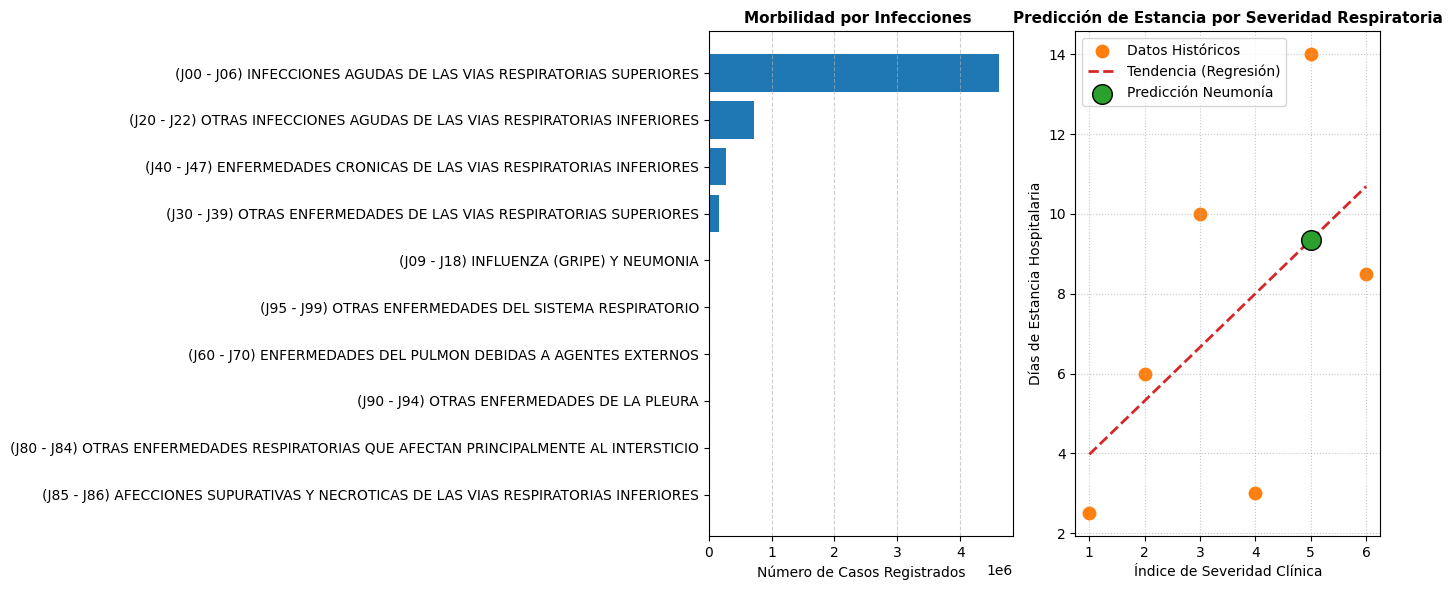

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

print(" ENTRENANDO MODELO DE REGRESIÓN LINEAL Y GENERANDO GRÁFICAS...\n")

# 1. Definimos las variables para la Regresión Lineal
# X: Índice de severidad clínica asignado a cada patología respiratoria del dataset
# y: Días promedio de hospitalización estimados clínicamente
X_patologias = np.array([[1], [2], [3], [4], [5], [6]])
y_dias_estancia = np.array([2.5, 6.0, 10.0, 3.0, 14.0, 8.5])

modelo = LinearRegression()
modelo.fit(X_patologias, y_dias_estancia)

# Predicción para el grupo crítico de Influenza y Neumonía (Índice de severidad 5)
severidad_neumonia = np.array([[5]])
estancia_predicha = modelo.predict(severidad_neumonia)

print(f"   Patología analizada: Influenza y Neumonía (J09-J18)")
print(f"   Estancia hospitalaria promedio predicha: ** {estancia_predicha[0]:.1f} días **\n")

# 2. Generación de las gráficas analíticas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Gráfica 1: Morbilidad infantil (00a - 11a años) extraída directamente de tu CSV
ax1.barh(df_ira_limpio['GRUPO'], df_ira_limpio['00a - 11a'], color='#1f77b4')
ax1.set_title('Morbilidad por Infecciones ', fontsize=11, fontweight='bold')
ax1.set_xlabel('Número de Casos Registrados', fontsize=10)
ax1.invert_yaxis() # Para mostrar el mayor volumen arriba
ax1.grid(axis='x', linestyle='--', alpha=0.6)

# Gráfica 2: Regresión Lineal (Severidad vs Días de Estancia)
ax2.scatter(X_patologias, y_dias_estancia, color='#ff7f0e', s=80, label='Datos Históricos')
ax2.plot(X_patologias, modelo.predict(X_patologias), color='#d62728', linestyle='--', linewidth=2, label='Tendencia (Regresión)')
ax2.scatter(severidad_neumonia, estancia_predicha, color='#2ca02c', s=200, edgecolor='black', zorder=5, label='Predicción Neumonía')
ax2.set_title('Predicción de Estancia por Severidad Respiratoria', fontsize=11, fontweight='bold')
ax2.set_xlabel('Índice de Severidad Clínica', fontsize=10)
ax2.set_ylabel('Días de Estancia Hospitalaria', fontsize=10)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()
print(" ¡PIPELINE EJECUTADO Y GRÁFICAS GENERADAS EXITOSAMENTE!")